# TLE to SP3 conversion, SP3 comparison and NORAD ID assignment

This notebook shows how to use two `pygnss` tools:

| Tool | Python API | Purpose |
|------|------------|---------|
| `tle_to_sp3` | `pygnss.orbit.tle_to_sp3` | Propagate Two-Line Elements (TLE) with SGP4 and write SP3-d orbit files |
| `sp3` | `pygnss.orbit.sp3` | Compare two SP3 files (radial / along-track / cross-track) and reassign satellite IDs |

They are applied to real data to answer a practical question: **which NORAD catalog number corresponds to
each satellite of a LEO constellation whose SP3 files only carry an anonymous ID?**

The real data are the Spire (Lemur-2) orbits distributed by UCAR/COSMIC, where every SP3 file labels the
satellite as `L99` and the actual platform is only given by the file name. The answer is found by
*orbit matching*: build one SP3 per NORAD candidate from its TLEs and keep the one with the lowest
position RMS with respect to the Spire orbit.

**Contents**
1. Setup and dataset
2. Command line usage
3. Python API: TLE to SP3, joining and comparing orbits
4. Orbit matching: NORAD ID assignment
5. Quality of the TLE orbits (RTN statistics)

> **Dataset**: the TLEs, the satellite list and the results of this notebook are archived in Zenodo
> (see `tle_to_sp3/README.md`). The Spire orbits are downloaded from the original
> UCAR/COSMIC archive (not redistributed). The notebook downloads both automatically if missing.

## 1. Setup and dataset

Install `pygnss` if it is not installed yet (from the repository root use `pip install -e .`).

In [1]:
try:
    import pygnss  # noqa: F401
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pygnss", "matplotlib"])

In [ ]:
import datetime
import io
import os
import tarfile
import tempfile
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pygnss.orbit.sp3 import compare, read_sp3, rms_stats
from pygnss.orbit.tle import read_celestrak
from pygnss.orbit.tle_to_sp3 import build_sp3, write_sp3_files

# Works whether the notebook is run from `notebooks/` or from the repository root
BASE_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
DATA_DIR = BASE_DIR / "tle_to_sp3"

# Zenodo record with the TLEs, the satellite list and the results (replace by the real record ID once published)
ZENODO_RECORD = "23287620"
ZENODO_DOI = f"10.5281/zenodo.{ZENODO_RECORD}"
ZENODO_URL = f"https://zenodo.org/records/{ZENODO_RECORD}/files/tle_to_sp3_data.zip"

# Spire orbits are NOT redistributed in Zenodo: they are downloaded from the original UCAR/COSMIC archive
UCAR_URL = "https://data.cosmic.ucar.edu/gnss-ro/spire/noaa/nrt/level1b/2026/279/leoOrb_nrt_2026_279.tar.gz"

SPIRE_DIR = DATA_DIR / "leoOrb_nrt_2026_279"
TLE_DIR = DATA_DIR / "spire_tle_celestrak"

if not TLE_DIR.exists():
    print(f"Downloading dataset doi:{ZENODO_DOI} ...")
    with urllib.request.urlopen(ZENODO_URL) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall(BASE_DIR)

if not SPIRE_DIR.exists():
    print(f"Downloading Spire orbits from {UCAR_URL} ...")
    SPIRE_DIR.mkdir(parents=True)
    with urllib.request.urlopen(UCAR_URL) as response:
        with tarfile.open(fileobj=io.BytesIO(response.read()), mode="r:gz") as tar:
            tar.extractall(SPIRE_DIR, filter="data")

# Outputs of this notebook
SP3_DIR = DATA_DIR / "sp3_from_tle"
PLOT_DIR = DATA_DIR / "plots"
SP3_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data folder: {DATA_DIR.resolve()}")

### Input data

**Spire orbits (SP3).** Level 1b NRT orbit products from UCAR/COSMIC, one tarball per day:

```
https://data.cosmic.ucar.edu/gnss-ro/spire/noaa/nrt/level1b/%Y/%j/leoOrb_nrt_%Y_%j.tar.gz
```

We use **2026-10-06 (DOY 279)**. Inside the tarball the file names follow
`leoOrb_<year>.<doy>.<platform>.<nn>_<seg>.<seg>_sp3`. The satellite is always labelled `L99` *inside* the SP3;
the platform number (e.g. `173`) is only in the file name, and each platform is split in several segments.

**TLEs (Celestrak).** One 3-line file per NORAD ID covering 2026-10-05 to 2026-10-07, obtained with a Celestrak GP
history request (the result is sent by e-mail). The list of Spire NORAD IDs (`celestrak_spire_satellites.csv`)
comes from <https://celestrak.org/NORAD/elements/active.txt>.

In [3]:
names = pd.read_csv(DATA_DIR / "celestrak_spire_satellites.csv").set_index("NORAD")["Name"]
spire_files = sorted(SPIRE_DIR.glob("leoOrb_2026.279.*_sp3"))
tle_files = sorted(TLE_DIR.glob("*.txt"))

spire_ids = sorted({f.name.split("_")[1].split(".")[2] for f in spire_files})
print(f"{len(spire_files)} Spire files, {len(spire_ids)} platforms, {len(names)} NORAD candidates")
print(f"Example platform IDs: {spire_ids[:8]}")

300 Spire files, 23 platforms, 92 NORAD candidates
Example platform IDs: ['173', '174', '196', '197', '199', '201', '202', '205']


## 2. Command line usage

Both tools are installed as console scripts (`tle_to_sp3` and `sp3`).

In [4]:
!tle_to_sp3 --help

usage: tle_to_sp3 [-h] -o OUTPUT [--start START] [--end END]
                  [--interval INTERVAL] [--agency AGENCY] [--frame FRAME]
                  [--sat-id NORAD=SATID] [--along-km ALONG_KM]
                  [--along-km-per-day ALONG_KM_PER_DAY]
                  tle_files [tle_files ...]

Convert Two-Line Elements (TLE) into SP3-d orbit files (ECEF positions with an
error estimate), propagating the TLEs with SGP4.

Format reference: https://files.igs.org/pub/data/format/sp3d.pdf

Notes:

- SP3 satellite identifiers only have two digits, so satellites are named
  ``Lnn`` (``L`` is the LEO constellation letter) and the mapping to NORAD
  catalog numbers is stored in the ``/*`` comment lines as ``NORAD Lnn=id``.
- SGP4 outputs TEME coordinates, that are rotated to ECEF with the GMST angle
  (polar motion neglected, which is far below the TLE accuracy).
- The error is a simple empirical model that grows linearly with the time
  distance to the TLE epoch. It is reported as the 1-si

Convert the TLEs of one satellite (NORAD 60533) into an SP3 file naming it `L99` like Spire does. The epochs (`--start`, `--end`, `--interval`) are chosen to match the first segment of Spire platform `173` (21:52:19 to 00:52:19, every 60 s), so both files have common epochs:

In [5]:
tle_60533 = TLE_DIR / "sat000060533.txt"
cli_sp3 = SP3_DIR / "cli_60533.sp3"

!tle_to_sp3 {tle_60533} -o {cli_sp3} --start "2026-10-05 21:52:19" --end "2026-10-06 00:52:19" --interval 60 --sat-id 60533=L99

tle_to_sp3/sp3_from_tle/cli_60533.sp3


Compare it with the first Spire segment of platform `173`. `sp3 compare` expresses the difference in the
radial / along-track / cross-track (RTN) frame defined by the **reference** file and prints RMS statistics
(`--epochs-output` and `--stats-output` store per-epoch differences and statistics as CSV):

In [6]:
spire_173_first = SPIRE_DIR / "leoOrb_2026.279.173.00_0001.0001_sp3"

!sp3 compare {spire_173_first} {cli_sp3}

Position RMS [m] (radial = nadir direction)
     epochs       3D   radial    along    cross
sat                                            
L99     181 413.9087 123.1720 360.8692 161.0045
ALL     181 413.9087 123.1720 360.8692 161.0045


`sp3 reassign` rewrites the satellite ID of an SP3 file, e.g. to label the Spire segment as `L01` instead of `L99`:

In [7]:
!sp3 reassign {spire_173_first} L99 L01 -o {SP3_DIR / "spire_173_L01.sp3"}

363 replacements: L99 -> L01 (tle_to_sp3/sp3_from_tle/spire_173_L01.sp3)


## 3. Python API

SP3 IDs only have two digits, so `tle_to_sp3` names satellites `Lnn` and keeps the NORAD ID in the SP3
comment lines (`NORAD Lnn=id`).

### 3.1 TLE to SP3 (one file per NORAD ID, whole day)

In [8]:
date = datetime.date(2026, 10, 6)
start = datetime.datetime.combine(date, datetime.time())
end = start + datetime.timedelta(days=1) - datetime.timedelta(seconds=300)

for tle_file in tle_files:
    tles = read_celestrak(str(tle_file))
    for norad_id in sorted({tle.id for tle in tles}):
        sat_tles = [tle for tle in tles if tle.id == norad_id]
        out = SP3_DIR / date.strftime(f"tle_%Y.%j.{norad_id}.sp3")
        # Spire convention for the satellite ID (L99) instead of a sequential one
        write_sp3_files(sat_tles, str(out), start=start, end=end, interval_s=300.0,
                        sat_id_map={norad_id: "L99"})

print(f"{len(list(SP3_DIR.glob('tle_2026.279.*.sp3')))} SP3 files written in {SP3_DIR}")

92 SP3 files written in tle_to_sp3/sp3_from_tle


### 3.2 Join the Spire segments

Segments of each platform are joined (and de-duplicated) in a data frame indexed by `(epoch, sat)`.

In [9]:
spire_orbits = {}
for f in spire_files:
    spire_id = f.name.split("_")[1].split(".")[2]
    spire_orbits.setdefault(spire_id, []).append(read_sp3(str(f)))
spire_orbits = {k: pd.concat(v)[lambda d: ~d.index.duplicated()].sort_index() for k, v in spire_orbits.items()}

spire_orbits["173"].head()

,,x,y,z,vx,vy,vz
epoch,sat,,,,,,
2026-10-05 21:52:19,L99,-4478005.718,-833870.993,-5196282.580,5150.017321,2859.706215,-4900.476402
2026-10-05 21:53:19,L99,-4158811.028,-661993.727,-5478802.035,5485.961481,2866.979657,-4513.458299
2026-10-05 21:54:19,L99,-3820166.875,-490138.109,-5737509.109,5798.082491,2859.021929,-4107.019451
2026-10-05 21:55:19,L99,-3463546.587,-319210.511,-5971291.355,6084.934190,2836.095835,-3682.932049
2026-10-05 21:56:19,L99,-3090506.908,-150099.252,-6179144.770,6345.182784,2798.539830,-3243.037337


### 3.3 Compare two orbits

`build_sp3` accepts **explicit epochs**, so the TLE orbit is evaluated exactly at the epochs of the reference
file. `compare` returns ECEF differences, RTN components and the 3D norm per epoch; `rms_stats` summarises them.

In [10]:
tles_by_norad = {}
for tle_file in tle_files:
    for tle in read_celestrak(str(tle_file)):
        tles_by_norad.setdefault(tle.id, []).append(tle)


def tle_orbit(norad_id, epochs):
    """SP3 data frame of a NORAD ID evaluated at the given epochs (satellite labelled L99)"""
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "candidate.sp3")
        with open(path, "w") as fh:
            fh.write(build_sp3(tles_by_norad[norad_id], epochs=list(epochs), sat_id_map={norad_id: "L99"}))
        return read_sp3(path)


reference = spire_orbits["173"]
epochs = reference.index.get_level_values("epoch").unique()
diffs = compare(reference, tle_orbit(60533, epochs))
rms_stats(diffs).round(1)

,epochs,3D,radial,along,cross
sat,,,,,
L99,1603,597.1,126.8,558.1,170.3
ALL,1603,597.1,126.8,558.1,170.3


## 4. Orbit matching: NORAD ID assignment

For each Spire platform, the Spire orbit (decimated, to keep it fast) is compared against the TLE orbit of
**every** NORAD candidate at the Spire epochs. The candidate with the lowest 3D RMS is assigned to the platform.
`ratio` = (second best RMS) / (best RMS) tells how unambiguous the match is.

In [11]:
DECIMATION = 5
rms_3d = pd.DataFrame(index=sorted(spire_orbits), columns=sorted(tles_by_norad), dtype=float)

for spire_id, spire_orbit in spire_orbits.items():
    epochs = spire_orbit.index.get_level_values("epoch").unique()[::DECIMATION]
    ref = spire_orbit.loc[epochs]
    for norad_id in tles_by_norad:
        d = compare(ref, tle_orbit(norad_id, epochs))
        rms_3d.loc[spire_id, norad_id] = np.sqrt((d["norm"] ** 2).mean()) if not d.empty else np.nan

In [12]:
best = rms_3d.idxmin(axis=1)
sorted_rms = np.sort(rms_3d.to_numpy(), axis=1)

assignment = pd.DataFrame({
    "norad_id": best,
    "name": best.map(names),
    "rms_3d_km": sorted_rms[:, 0] / 1e3,
    "second_best_rms_3d_km": sorted_rms[:, 1] / 1e3,
})
assignment.index.name = "spire_id"
assignment["ratio"] = assignment["second_best_rms_3d_km"] / assignment["rms_3d_km"]
assignment["duplicated_norad"] = assignment["norad_id"].duplicated(keep=False)

assignment.to_csv(DATA_DIR / "spire_norad_assignment.csv")
assignment.round(3)

,norad_id,name,rms_3d_km,second_best_rms_3d_km,ratio,duplicated_norad
spire_id,,,,,,
173,60533,LEMUR-2-STELLA,0.597,1395.526,2337.204,False
174,60536,LEMUR-2-MARHISYAM,0.637,1652.545,2594.548,False
196,60577,LEMUR-2-LLOYD,0.628,820.267,1306.352,False
197,60579,LEMUR-2-SIERRINI,0.647,1435.285,2217.120,False
199,60576,LEMUR-2-AHMED-ASRAR,0.653,1443.643,2210.451,False
201,62696,LEMUR-2-STAR-FOX,0.612,1365.824,2230.207,False
202,62699,LEMUR-2-ARIANNA,0.624,1365.616,2189.794,False
205,62706,LEMUR-2-ALISIA,0.552,2467.697,4472.082,False
206,62711,LEMUR-2-ROUNDTRIPPER,0.638,752.974,1179.984,False


**Sanity checks**: every platform should get a different NORAD ID (`duplicated_norad == False`) and a large
`ratio` (a wrong satellite is thousands of km away, the right one is within a few km).
Check the platforms with a low `ratio` or a high RMS (e.g. `253`) individually: they may be affected by
a stale TLE, a manoeuvre or a missing candidate.

Duplicated NORAD IDs : 0
Minimum ratio        : 620.0
Median 3D RMS [km]   : 0.624


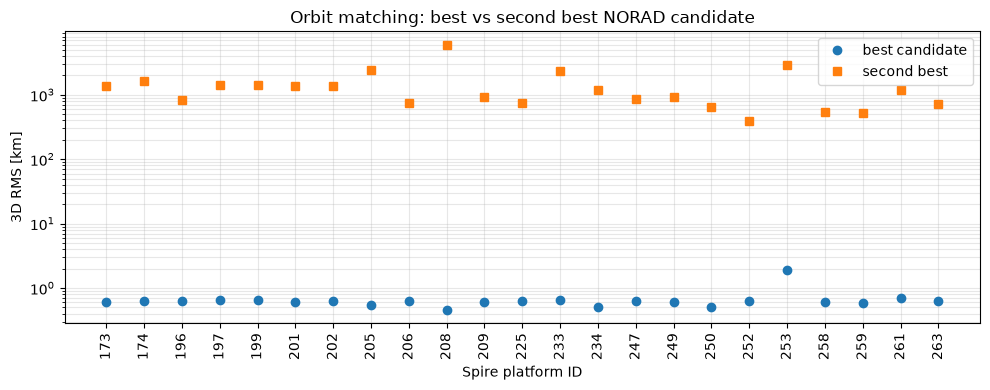

In [13]:
print("Duplicated NORAD IDs :", int(assignment["duplicated_norad"].sum()))
print("Minimum ratio        :", round(assignment["ratio"].min(), 1))
print("Median 3D RMS [km]   :", round(assignment["rms_3d_km"].median(), 3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(range(len(assignment)), assignment["rms_3d_km"], "o", label="best candidate")
ax.semilogy(range(len(assignment)), assignment["second_best_rms_3d_km"], "s", label="second best")
ax.set_xticks(range(len(assignment)))
ax.set_xticklabels(assignment.index, rotation=90)
ax.set_xlabel("Spire platform ID")
ax.set_ylabel("3D RMS [km]")
ax.set_title("Orbit matching: best vs second best NORAD candidate")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "matching_rms.png", dpi=120)
plt.show()

### Use the assignment

`spire_norad_assignment.csv` translates a platform ID into a NORAD ID, which can be used with the `--sat-id`
option of `tle_to_sp3`:

In [14]:
assignment.loc[["173", "208"], ["norad_id", "name"]]

,norad_id,name
spire_id,,
173,60533,LEMUR-2-STELLA
208,63262,LEMUR-2-MARACHE-FRAN


## 5. Quality of the TLE orbits (RTN)

With the assignment, the TLE orbit is compared with the Spire orbit at **all** its epochs.

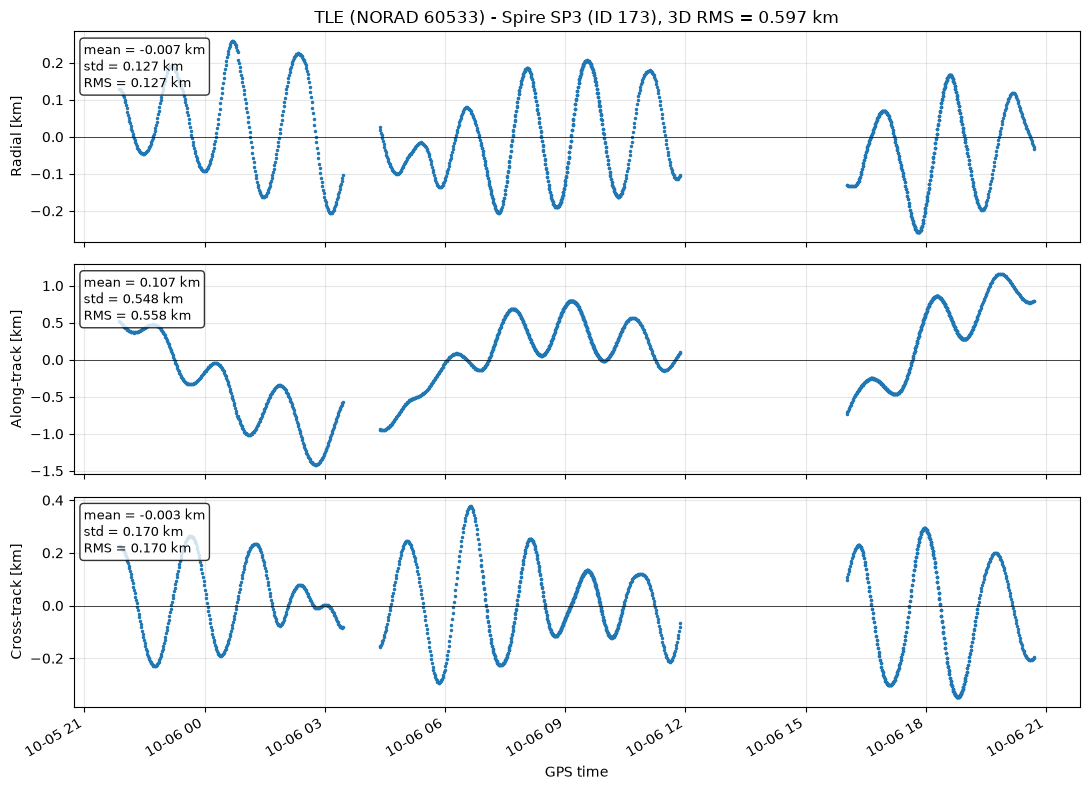

In [15]:
spire_id = "173"
norad_id = int(assignment.loc[spire_id, "norad_id"])

reference = spire_orbits[spire_id]
diffs = compare(reference, tle_orbit(norad_id, reference.index.get_level_values("epoch").unique())).droplevel("sat")

components = {"radial": "Radial", "along": "Along-track", "cross": "Cross-track"}
fig, axes = plt.subplots(len(components), 1, figsize=(11, 8), sharex=True)
for ax, (col, label) in zip(axes, components.items()):
    values = diffs[col]
    ax.plot(values.index, values / 1e3, ".", markersize=3)
    ax.axhline(0, color="k", linewidth=0.5)
    ax.set_ylabel(f"{label} [km]")
    ax.grid(True, alpha=0.3)
    stats = (f"mean = {values.mean() / 1e3:.3f} km\n"
             f"std = {values.std() / 1e3:.3f} km\n"
             f"RMS = {np.sqrt((values ** 2).mean()) / 1e3:.3f} km")
    ax.text(0.01, 0.95, stats, transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

rms_3d_km = np.sqrt((diffs["norm"] ** 2).mean()) / 1e3
axes[0].set_title(f"TLE (NORAD {norad_id}) - Spire SP3 (ID {spire_id}), 3D RMS = {rms_3d_km:.3f} km")
axes[-1].set_xlabel("GPS time")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PLOT_DIR / f"diff_{spire_id}_{norad_id}.png", dpi=120)
plt.show()

### Statistics for the whole constellation

In [16]:
rows = {}
for spire_id, row in assignment.iterrows():
    reference = spire_orbits[spire_id]
    epochs = reference.index.get_level_values("epoch").unique()
    d = compare(reference, tle_orbit(int(row["norad_id"]), epochs))
    rows[spire_id] = rms_stats(d).loc["ALL", ["epochs", "radial", "along", "cross", "3D"]]

constellation_stats = pd.DataFrame(rows).T
constellation_stats.index.name = "spire_id"
constellation_stats.insert(0, "norad_id", assignment["norad_id"])
constellation_stats.to_csv(DATA_DIR / "spire_tle_rms_rtn.csv")

(constellation_stats[["radial", "along", "cross", "3D"]] / 1e3).describe().loc[["mean", "50%", "max"]].round(3)

,radial,along,cross,3D
mean,0.115,0.630,0.160,0.663
50%,0.112,0.592,0.158,0.625
max,0.144,1.887,0.222,1.899


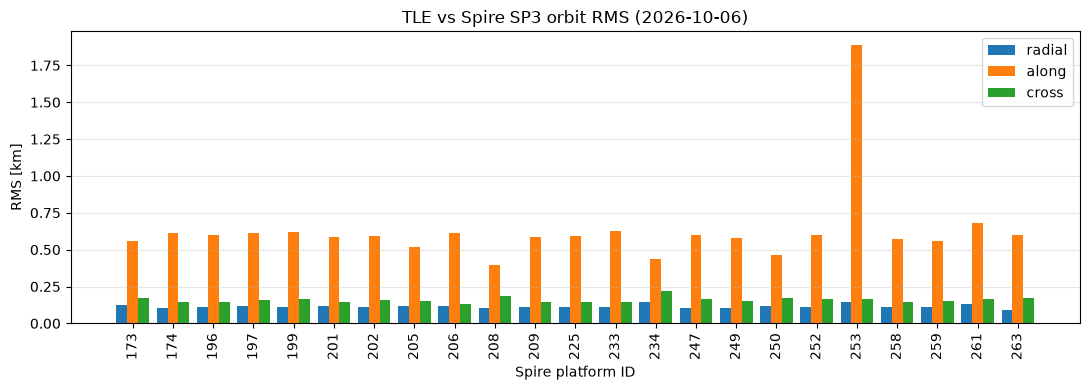

In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.27
x = np.arange(len(constellation_stats))
for i, col in enumerate(["radial", "along", "cross"]):
    ax.bar(x + (i - 1) * width, constellation_stats[col] / 1e3, width, label=col)
ax.set_xticks(x)
ax.set_xticklabels(constellation_stats.index, rotation=90)
ax.set_xlabel("Spire platform ID")
ax.set_ylabel("RMS [km]")
ax.set_title("TLE vs Spire SP3 orbit RMS (2026-10-06)")
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "constellation_rms_rtn.png", dpi=120)
plt.show()

## Reproducibility

* TLEs, satellite list and results: Zenodo dataset (see `tle_to_sp3/README.md`), DOI `10.5281/zenodo.23287620`.
* Spire orbits: UCAR/COSMIC Spire NOAA NRT level 1b, downloaded from the original archive (cite the source).
* TLEs: Celestrak GP history.
* Software: `pygnss` (`pygnss.orbit.tle_to_sp3`, `pygnss.orbit.sp3`) with `sgp4`.